In [1]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/Datasets/Solar/processed'

daily_plant = pd.read_csv(f'{DATA_DIR}/daily_plant_performance.csv')
daily_inverter = pd.read_csv(f'{DATA_DIR}/daily_inverter_performance.csv')
inverter_health = pd.read_csv(f'{DATA_DIR}/inverter_health_summary.csv')
alerts = pd.read_csv(f'{DATA_DIR}/underperformance_alerts.csv')

print(f"daily_plant: {len(daily_plant)} rows")
print(f"daily_inverter: {len(daily_inverter)} rows")
print(f"inverter_health: {len(inverter_health)} rows")
print(f"alerts: {len(alerts)} rows")

Mounted at /content/drive
daily_plant: 68 rows
daily_inverter: 1464 rows
inverter_health: 44 rows
alerts: 232 rows


In [2]:
import numpy as np

daily_plant['DATE'] = pd.to_datetime(daily_plant['DATE'])
daily_inverter['DATE'] = pd.to_datetime(daily_inverter['DATE'])
alerts['DATE'] = pd.to_datetime(alerts['DATE'])

total_days = daily_plant['DATE'].nunique()
total_inverters = daily_inverter['SOURCE_KEY'].nunique()
total_inverter_days = len(daily_inverter)

# KPI CALCULATIONS
portfolio_pr = daily_inverter['total_ac_kwh'].sum() / (daily_inverter['plant_avg_ac'].sum())
pr_target = 0.95

producing_days = (daily_inverter['total_ac_kwh'] > 0).sum()
availability = producing_days / total_inverter_days * 100
avail_target = 98.0

underperf_rate = len(alerts) / total_inverter_days * 100
underperf_target = 5.0

total_lost_kwh = daily_inverter['lost_kwh'].sum()
lost_target = 50.0

expected_records = 22 * total_days * 2
data_completeness = total_inverter_days / expected_records * 100
completeness_target = 99.0

total_lost_revenue_ppa = daily_inverter['lost_revenue_usd'].sum()

srec_rate = 70
lost_mwh = total_lost_kwh / 1000
lost_srec_revenue = lost_mwh * srec_rate

total_revenue_impact = total_lost_revenue_ppa + lost_srec_revenue

repeat_offenders = (inverter_health['underperforming_days'] >= 3).sum()
repeat_rate = repeat_offenders / total_inverters * 100
repeat_target = 10.0

worst_pr = inverter_health['avg_pr'].min()
worst_inverter = inverter_health.loc[inverter_health['avg_pr'].idxmin(), 'SOURCE_KEY']

def status(actual, target, higher_is_better=True):
    if higher_is_better:
        if actual >= target:
            return 'On Target'
        elif actual >= target * 0.9:
            return 'Monitor'
        else:
            return 'Needs Attention'
    else:
        if actual <= target:
            return 'On Target'
        elif actual <= target * 1.2:
            return 'Monitor'
        else:
            return 'Needs Attention'

print("=" * 75)
print("   SOLAR PORTFOLIO KPI SCORECARD")
print("=" * 75)
print(f"   Reporting Period: {daily_plant['DATE'].min().date()} to {daily_plant['DATE'].max().date()}")
print(f"   Plants: 2 | Inverters: {total_inverters} | Days: {total_days}")
print("=" * 75)

kpis = [
    ("Portfolio Performance Ratio", f"{portfolio_pr:.3f}", f"{pr_target:.2f}", status(portfolio_pr, pr_target)),
    ("Inverter Availability", f"{availability:.1f}%", f"{avail_target:.0f}%", status(availability, avail_target)),
    ("Underperformance Event Rate", f"{underperf_rate:.1f}%", f"<{underperf_target:.0f}%", status(underperf_rate, underperf_target, False)),
    ("Total Lost Energy", f"{total_lost_kwh:.1f} kWh", f"<{lost_target:.0f} kWh", status(total_lost_kwh, lost_target, False)),
    ("Data Completeness", f"{data_completeness:.1f}%", f"{completeness_target:.0f}%", status(data_completeness, completeness_target)),
    ("Lost Revenue (PPA)", f"${total_lost_revenue_ppa:.2f}", "---", "---"),
    ("Lost Revenue (SREC)", f"${lost_srec_revenue:.2f}", "---", "---"),
    ("Total Revenue Impact", f"${total_revenue_impact:.2f}", "---", "---"),
    ("Repeat Offender Rate", f"{repeat_rate:.1f}%", f"<{repeat_target:.0f}%", status(repeat_rate, repeat_target, False)),
    ("Worst Inverter PR", f"{worst_pr:.3f} ({worst_inverter[:10]})", ">0.85", status(worst_pr, 0.85)),
]

print(f"\n{'KPI':<35} {'Actual':<20} {'Target':<15} {'Status'}")
print("-" * 85)
for name, actual, target, stat in kpis:
    print(f"{name:<35} {actual:<20} {target:<15} {stat}")

print(f"\n{'=' * 75}")
print("   SUMMARY")
print(f"{'=' * 75}")
on_target = sum(1 for _, _, _, s in kpis if s == 'On Target')
monitor = sum(1 for _, _, _, s in kpis if s == 'Monitor')
attention = sum(1 for _, _, _, s in kpis if s == 'Needs Attention')
scored = on_target + monitor + attention
print(f"   On Target:        {on_target}/{scored}")
print(f"   Monitor:          {monitor}/{scored}")
print(f"   Needs Attention:  {attention}/{scored}")

   SOLAR PORTFOLIO KPI SCORECARD
   Reporting Period: 2020-05-15 to 2020-06-17
   Plants: 2 | Inverters: 44 | Days: 34

KPI                                 Actual               Target          Status
-------------------------------------------------------------------------------------
Portfolio Performance Ratio         1.000                0.95            On Target
Inverter Availability               100.0%               98%             On Target
Underperformance Event Rate         15.8%                <5%             Needs Attention
Total Lost Energy                   561.6 kWh            <50 kWh         Needs Attention
Data Completeness                   97.9%                99%             Monitor
Lost Revenue (PPA)                  $22.46               ---             ---
Lost Revenue (SREC)                 $39.31               ---             ---
Total Revenue Impact                $61.77               ---             ---
Repeat Offender Rate                50.0%                <

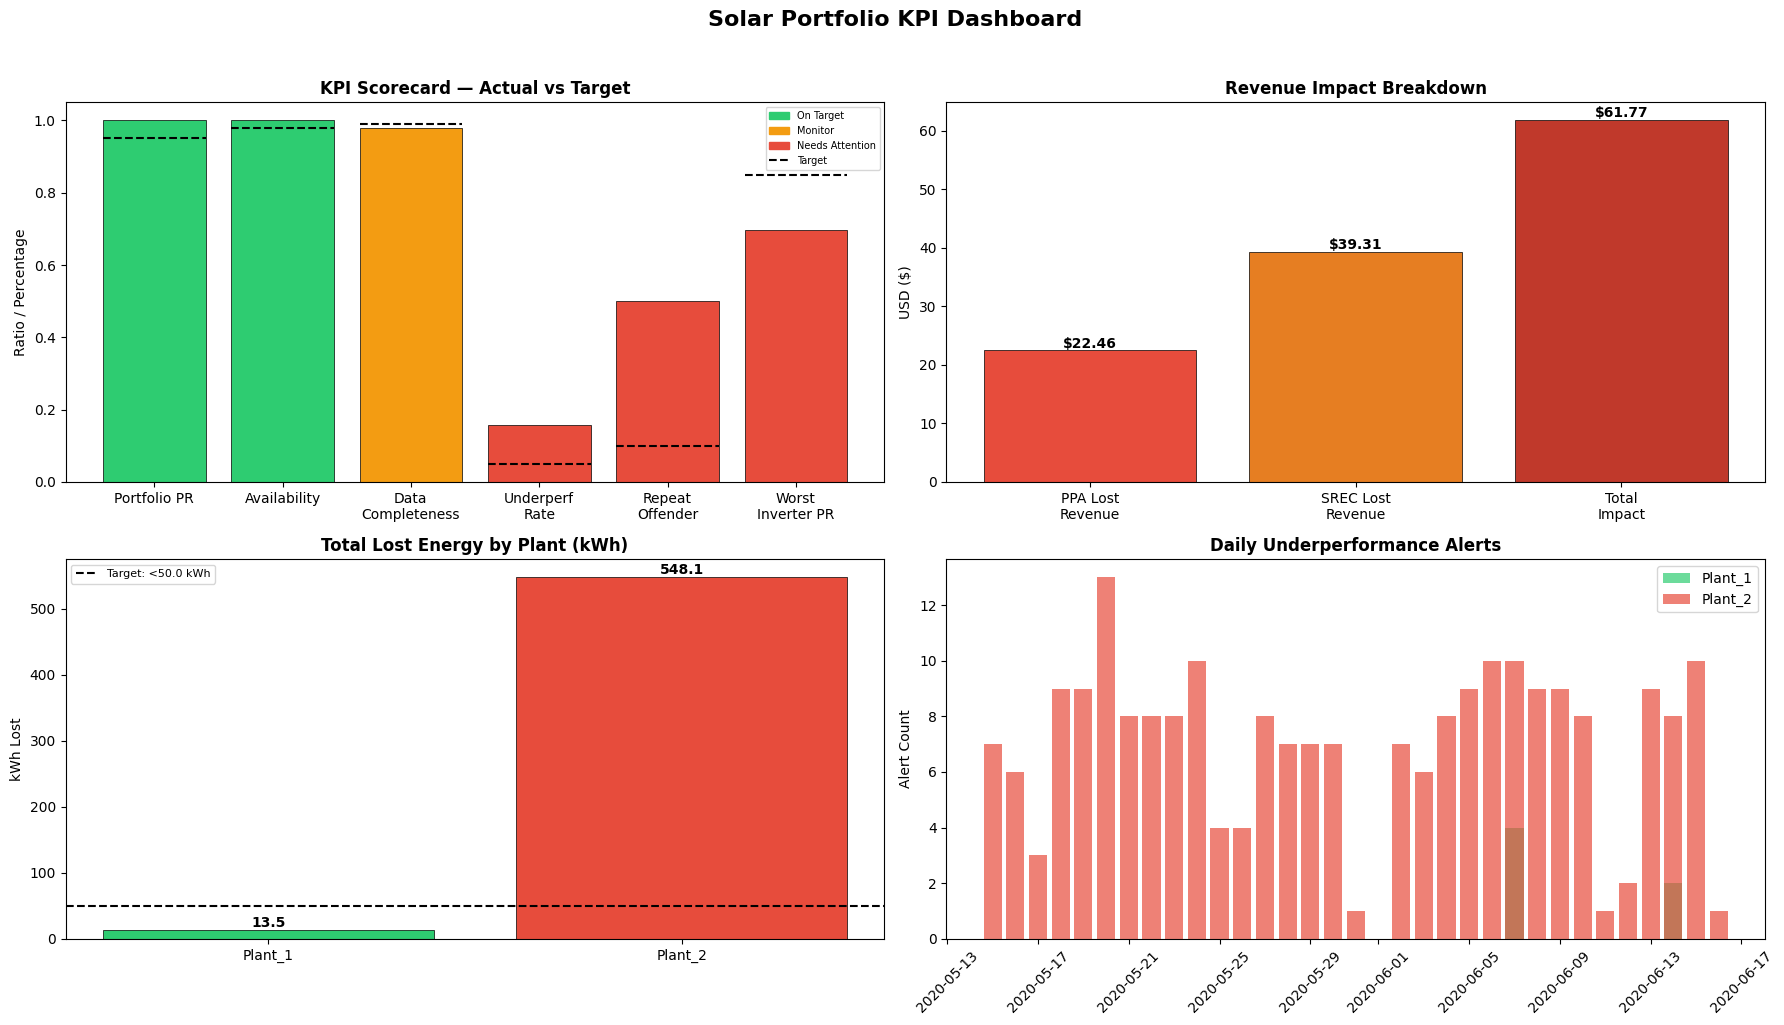

KPI Dashboard saved


In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
fig.suptitle('Solar Portfolio KPI Dashboard', fontsize=16, fontweight='bold', y=1.02)

# --- Panel 1: KPI Scorecard Bar Chart ---
kpi_names = ['Portfolio PR', 'Availability', 'Data\nCompleteness', 'Underperf\nRate', 'Repeat\nOffender', 'Worst\nInverter PR']
kpi_actuals = [portfolio_pr, availability/100, data_completeness/100, underperf_rate/100, repeat_rate/100, worst_pr]
kpi_targets = [0.95, 0.98, 0.99, 0.05, 0.10, 0.85]

bar_colors = []
for actual, target, name in zip(kpi_actuals, kpi_targets, kpi_names):
    if name in ['Underperf\nRate', 'Repeat\nOffender']:
        if actual <= target:
            bar_colors.append('#2ecc71')
        elif actual <= target * 1.2:
            bar_colors.append('#f39c12')
        else:
            bar_colors.append('#e74c3c')
    else:
        if actual >= target:
            bar_colors.append('#2ecc71')
        elif actual >= target * 0.9:
            bar_colors.append('#f39c12')
        else:
            bar_colors.append('#e74c3c')

axes[0,0].bar(kpi_names, kpi_actuals, color=bar_colors, edgecolor='black', linewidth=0.5)
for i, (name, target) in enumerate(zip(kpi_names, kpi_targets)):
    axes[0,0].plot([i-0.4, i+0.4], [target, target], 'k--', linewidth=1.5)
axes[0,0].set_title('KPI Scorecard — Actual vs Target', fontweight='bold')
axes[0,0].set_ylabel('Ratio / Percentage')
on_target_patch = mpatches.Patch(color='#2ecc71', label='On Target')
monitor_patch = mpatches.Patch(color='#f39c12', label='Monitor')
attention_patch = mpatches.Patch(color='#e74c3c', label='Needs Attention')
target_line = plt.Line2D([0], [0], color='black', linestyle='--', label='Target')
axes[0,0].legend(handles=[on_target_patch, monitor_patch, attention_patch, target_line], fontsize=7)

# --- Panel 2: Revenue Impact Breakdown ---
revenue_labels = ['PPA Lost\nRevenue', 'SREC Lost\nRevenue', 'Total\nImpact']
revenue_values = [total_lost_revenue_ppa, lost_srec_revenue, total_revenue_impact]
revenue_colors = ['#e74c3c', '#e67e22', '#c0392b']

bars = axes[0,1].bar(revenue_labels, revenue_values, color=revenue_colors, edgecolor='black', linewidth=0.5)
axes[0,1].set_title('Revenue Impact Breakdown', fontweight='bold')
axes[0,1].set_ylabel('USD ($)')
for bar, val in zip(bars, revenue_values):
    axes[0,1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                   f'${val:.2f}', ha='center', fontweight='bold')

# --- Panel 3: Lost Energy by Plant ---
plant_lost = daily_plant.groupby('PLANT_LABEL')['total_lost_kwh'].sum()
colors = ['#2ecc71', '#e74c3c']
bars = axes[1,0].bar(plant_lost.index, plant_lost.values, color=colors, edgecolor='black', linewidth=0.5)
axes[1,0].set_title('Total Lost Energy by Plant (kWh)', fontweight='bold')
axes[1,0].set_ylabel('kWh Lost')
axes[1,0].axhline(y=lost_target, color='black', linestyle='--', label=f'Target: <{lost_target} kWh')
axes[1,0].legend(fontsize=8)
for bar, val in zip(bars, plant_lost.values):
    axes[1,0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                   f'{val:.1f}', ha='center', fontweight='bold')

# --- Panel 4: Underperformance Events Over Time ---
daily_alerts = alerts.groupby(['DATE', 'PLANT_LABEL']).size().reset_index(name='alert_count')
for plant, color in [('Plant_1', '#2ecc71'), ('Plant_2', '#e74c3c')]:
    data = daily_alerts[daily_alerts['PLANT_LABEL'] == plant]
    axes[1,1].bar(data['DATE'], data['alert_count'], color=color, alpha=0.7, label=plant, width=0.8)
axes[1,1].set_title('Daily Underperformance Alerts', fontweight='bold')
axes[1,1].set_ylabel('Alert Count')
axes[1,1].legend()
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Datasets/Solar/processed/panel6_kpi_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("KPI Dashboard saved")

In [4]:
# KPI Scorecard as DataFrame
kpi_data = {
    'KPI': ['Portfolio Performance Ratio', 'Inverter Availability', 'Underperformance Event Rate',
            'Total Lost Energy', 'Data Completeness', 'Lost Revenue (PPA)', 'Lost Revenue (SREC)',
            'Total Revenue Impact', 'Repeat Offender Rate', 'Worst Inverter PR'],
    'Actual': [f"{portfolio_pr:.3f}", f"{availability:.1f}%", f"{underperf_rate:.1f}%",
               f"{total_lost_kwh:.1f} kWh", f"{data_completeness:.1f}%", f"${total_lost_revenue_ppa:.2f}",
               f"${lost_srec_revenue:.2f}", f"${total_revenue_impact:.2f}", f"{repeat_rate:.1f}%",
               f"{worst_pr:.3f} ({worst_inverter[:10]})"],
    'Target': ['0.95', '98%', '<5%', '<50 kWh', '99%', '---', '---', '---', '<10%', '>0.85'],
    'Status': ['On Target', 'On Target', 'Needs Attention', 'Needs Attention',
               'Monitor', '---', '---', '---', 'Needs Attention', 'Needs Attention']
}

kpi_df = pd.DataFrame(kpi_data)
kpi_df.to_csv('/content/drive/MyDrive/Datasets/Solar/processed/kpi_scorecard.csv', index=False)

print("KPI Scorecard saved!")
print(kpi_df.to_string(index=False))

KPI Scorecard saved!
                        KPI             Actual  Target          Status
Portfolio Performance Ratio              1.000    0.95       On Target
      Inverter Availability             100.0%     98%       On Target
Underperformance Event Rate              15.8%     <5% Needs Attention
          Total Lost Energy          561.6 kWh <50 kWh Needs Attention
          Data Completeness              97.9%     99%         Monitor
         Lost Revenue (PPA)             $22.46     ---             ---
        Lost Revenue (SREC)             $39.31     ---             ---
       Total Revenue Impact             $61.77     ---             ---
       Repeat Offender Rate              50.0%    <10% Needs Attention
          Worst Inverter PR 0.697 (Quc1TzYxW2)   >0.85 Needs Attention
